<a href="https://colab.research.google.com/github/mateosuster/pythonungs/blob/master/codigos/TPs/MPE_III_TP_3_resolucion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Matemática para Economistas III - UNGS
## TP N°3 - Propuesta de resolución

> **Nota:** lo que sigue es *una* propuesta de resolución, no *la* resolución. Cualquier alternativa que funcione y esté bien justificada es igual de válida.

## Ejercicio 1: Ahorro hasta la meta con `while`

**Datos del enunciado:** aporte mensual $A = \$120.000$ (se deposita al **inicio** de cada mes), TNA $= 40\%$ con capitalización mensual, meta $= \$3.000.000$.

La tasa efectiva mensual es

$$i = \frac{TNA}{12} = \frac{0{,}40}{12} \approx 0{,}0333 \quad (3{,}33\%\ \text{mensual})$$

Como el aporte entra al inicio del mes y la capitalización ocurre al final, el saldo evoluciona según

$$S_t = (S_{t-1} + A)\times(1+i)$$

**Estructura elegida para el registro:** una **lista de tuplas** `(mes, saldo)`. Preserva el orden cronológico, guarda el historial completo y después es fácil de recorrer para graficar. (Un diccionario `{mes: saldo}` también sería razonable.)

Se usa `while` porque **no sabemos a priori cuántos meses** lleva alcanzar la meta: el bucle sigue mientras el saldo esté por debajo de ella.

In [1]:
# --- EJERCICIO 1.2: SIMULACION MES A MES CON WHILE ---

# Parametros
aporte = 120_000        # A: aporte al inicio de cada mes
TNA = 0.40              # tasa nominal anual, capitalizacion mensual
i = TNA / 12            # tasa efectiva mensual
meta = 3_000_000

# Inicializacion
saldo = 0.0             # S_0 = 0
mes = 0
historial = []          # registro: lista de tuplas (mes, saldo)

# Bucle: avanza mientras el saldo no alcance la meta
while saldo < meta:
    mes += 1
    saldo = (saldo + aporte) * (1 + i)   # aporte al inicio + capitalizacion al final
    historial.append((mes, saldo))

# Resultados
aporte_total = aporte * mes
interes_ganado = saldo - aporte_total

print(f"Meses necesarios : {mes}")
print(f"Saldo final      : ${saldo:,.2f}")
print(f"Aporte total     : ${aporte_total:,.2f}")
print(f"Interes ganado   : ${interes_ganado:,.2f}")

Meses necesarios : 19
Saldo final      : $3,216,035.11
Aporte total     : $2,280,000.00
Interes ganado   : $936,035.11


**Lectura del resultado:** la meta se alcanza en el mes **19**, con un saldo de **$3.216.035,11**. El ahorrista aportó de su bolsillo $2.280.000 (19 aportes de $120.000) y el resto — **$936.035,11** — lo puso la capitalización de intereses, que terminó representando cerca del 41% del total aportado. Notar que en el último mes el saldo *se pasa* de la meta: el `while` corta en el primer mes en que $S_t \geq$ meta.

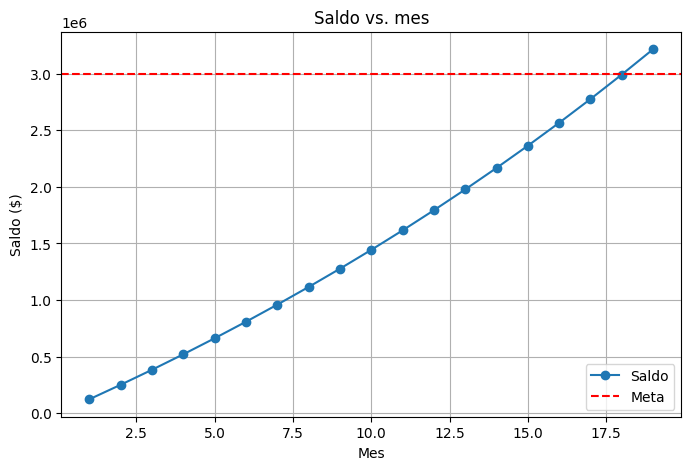

In [2]:
# --- EJERCICIO 1.3: GRAFICO SALDO VS MES ---
import matplotlib.pyplot as plt

# Extraer los datos del historial: recorremos la lista de tuplas con while
meses = []
saldos = []
j = 0
while j < len(historial):
    mes_j, saldo_j = historial[j]
    meses.append(mes_j)
    saldos.append(saldo_j)
    j += 1

plt.figure(figsize=(8, 5))
plt.plot(meses, saldos, marker='o', label='Saldo')
plt.axhline(meta, color='red', linestyle='--', label='Meta')
plt.xlabel('Mes')
plt.ylabel('Saldo ($)')
plt.title('Saldo vs. mes')
plt.legend()
plt.grid(True)
plt.show()

## Ejercicio 2: Analizar el algoritmo

### 2.1 ¿Qué hace y cómo?

El programa **encuentra e imprime el elemento máximo** de la secuencia `x`, recorriéndola una sola vez:

1. **Líneas 1-2:** guarda el largo `l` de `x` e inicializa `m` con el primer elemento, `x[0]`. La variable `m` funciona como **máximo parcial**.
2. **Líneas 3-7:** el `while` recorre los índices `1, 2, ..., l-1`. En cada paso compara `x[i]` con `m` y, si el elemento es mayor, actualiza `m`. El **invariante del ciclo** es: al terminar de procesar el índice `i`, `m` es el máximo de `x[0], x[1], ..., x[i]`.
3. **Línea 9:** imprime `m`, que al cortar el bucle es el máximo de toda la secuencia.

Es un algoritmo de **una sola pasada** (eficiencia lineal en el largo de `x`), no requiere que `x` esté ordenada, y **falla si la secuencia está vacía** (`x[0]` rompe con `IndexError`).

### 2.2 ¿Qué nombre le pondríamos?

Siguiendo las buenas prácticas de Python (minúsculas, palabras separadas por guión bajo, sin espacios, sin tildes, y sobre todo: que **describa** lo que hace), el nombre natural es:

**`maximo.py`** — o, más explícito, **`encontrar_maximo.py`**

Ninguna multinacional paga por `programa1_final_FINAL_v2(2).py`.

In [3]:
def maximo_de_secuencia(secuencia):
    """Devuelve el elemento de mayor valor de una secuencia no vacia.

    Recorre la secuencia una sola vez manteniendo un maximo parcial,
    tal como hace el algoritmo original del enunciado.

    Args:
        secuencia (sequence): secuencia no vacia de elementos comparables
            entre si (list, tuple, str, etc.).

    Returns:
        El elemento de mayor valor de la secuencia.
    """
    mayor = secuencia[0]           # maximo parcial: arranca en el primer elemento
    j = 1
    while j < len(secuencia):
        if secuencia[j] > mayor:   # encontro un candidato a maximo...
            mayor = secuencia[j]   # ...y lo guarda
        j += 1
    return mayor


# Prueba
x = [17, 3, 42, 8, 42, -1, 0]
print(maximo_de_secuencia(x))    # 42

# Nota: Python ya trae una funcion nativa equivalente. En la practica,
# para esto uno usaria max(x); el TP pide re-implementarla para entenderla.
print(max(x))                    # 42

42
42


### 2.4 ¿Qué tipo de datos admite la entrada?

Para que el algoritmo funcione, la entrada `x` debe:

1. ser **una secuencia**: soportar `len()` e indexación por posición (`x[0]`), y
2. contener elementos **comparables entre sí** con `>`,

y además no debe estar vacía. Probemos los cinco casos del enunciado y usemos `try/except` para atrapar (e interpretar) los errores:

In [4]:
casos = [
    ("un numero real", 3.14),
    ("una tupla de numeros", (1, 5, 3, 9, 2)),
    ("una lista con numeros y strings", [1, "a", 3, "b", 2]),
    ("un string", "hola"),
    ("un diccionario", {"a": 1, "b": 2}),
]

# Recorremos los casos con while, probando la funcion en cada uno
j = 0
while j < len(casos):
    descripcion, dato = casos[j]
    try:
        resultado = maximo_de_secuencia(dato)
        print(f"{descripcion:38s} -> OK: {resultado!r}")
    except Exception as error:
        print(f"{descripcion:38s} -> {type(error).__name__}: {error}")
    j += 1

un numero real                         -> TypeError: 'float' object is not subscriptable
una tupla de numeros                   -> OK: 9
una lista con numeros y strings        -> TypeError: '>' not supported between instances of 'str' and 'int'
un string                              -> OK: 'o'
un diccionario                         -> KeyError: 0


Caso por caso:

- **Número real (`3.14`):** rompe con `TypeError: 'float' object is not subscriptable`. Un `float` no es una secuencia: no tiene largo ni se puede indexar. (Nuestra función, que arranca indexando con `secuencia[0]`, falla ahí; el algoritmo original del enunciado, que primero llama a `len(x)`, rompería con el mensaje gemelo: `object of type 'float' has no len()`. En ambos casos el motivo de fondo es el mismo.)
- **Tupla de números:** ¡funciona! Devuelve `9`. Las tuplas son secuencias indexables y sus números se comparan entre sí sin problemas.
- **Lista con números y strings:** rompe con `TypeError: '>' not supported between instances of 'str' and 'int'`. En Python 3 no está definido comparar un string con un número, y ese `if x[i] > m` llega tarde o temprano (salvo en casos patológicos, como que el string nunca se compare con un número).
- **String (`"hola"`):** ¡también funciona! Un string es una secuencia de caracteres, y los caracteres se comparan por su código Unicode. Devuelve `'o'`, la "letra más grande" de `"hola"`. La salida ya no es un número sino un string de largo 1.
- **Diccionario:** rompe con `KeyError: 0`. Un dict tiene `len()`, pero `x[0]` no pide "la posición 0": busca la **clave** `0`, que no existe. Los diccionarios se indexan por clave, no por posición.

**Conclusión:** la entrada válida es cualquier **secuencia no vacía de elementos mutuamente comparables** (listas, tuplas, strings); la salida es siempre un elemento del mismo tipo que los de la secuencia de entrada.